# CLFG hourly forcing comparison

Select the native HRRR-AK and downscaled cells that contain CLFG. The full-year panels use daily means and daily precipitation totals. Set frequency to None and choose a shorter interval to inspect hourly behavior. The fallback series marks when the adapter used a surface-only lapse-rate adjustment. The CSV keeps hourly values.

In [1]:
from pathlib import Path
import sys
cwd = Path.cwd()
candidates = (cwd, cwd / "downscaling", cwd / "jif_snow_modeling" / "downscaling")
folder = next((path for path in candidates if (path / "icefield_comparison.py").is_file()), None)
if folder is None:
    raise FileNotFoundError(
        "Open this notebook from the repos workspace, jif_snow_modeling, or its downscaling folder."
    )
sys.path.insert(0, str(folder))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from icefield_comparison import RUN, RESOLUTIONS, edges, lookup, raw_geometry, raw_path, site

year = 2026
project = RUN / f"WY{year}"
output = folder / "outputs"
output.mkdir(exist_ok=True)
terrains = [project / f"{m}m/terrain.nc" for m in RESOLUTIONS]
forcings = [project / f"{m}m/forcing.nc" for m in RESOLUTIONS]
surface_path = project / "surface_native.nc"
from pyproj import Proj
from icefield_comparison import ALASKA_GRID

start, end = f"{year-1}-10-01", f"{year}-09-30"
frequency = "D"
finished = [m for m, fp, tp in zip(RESOLUTIONS, forcings, terrains) if fp.exists() and tp.exists()]
ready = bool(finished) and surface_path.exists()
frames = {}
if not ready:
    print("Waiting for the first complete annual forcing product.")
else:
    cells = lookup(year, finished)
    display(cells[["elevation_m","reference_elevation_m","cell_minus_reference_m"]].round(2))
    i, j = cells.iloc[0][["row","col"]].astype(int)
    with xr.open_dataset(surface_path) as source:
        s = source.isel(y=i, x=j).sel(time=slice(start,end)).load()
    gamma = np.deg2rad(Proj(ALASKA_GRID).get_factors(
        (float(s.longitude)+180)%360-180,float(s.latitude)).meridian_convergence)
    u = s["10u"].values*np.cos(gamma)+s["10v"].values*np.sin(gamma)
    v = -s["10u"].values*np.sin(gamma)+s["10v"].values*np.cos(gamma)
    frames["Native HRRR-AK"] = pd.DataFrame(dict(
        temperature=s.temp.values-273.15, rh=s.rh.values, wind=np.hypot(u,v),
        u_east=u, v_north=v, wind_direction=np.rad2deg(np.arctan2(-u,-v))%360,
        pressure=s.pressure.values/100, shortwave=s.swrad.values,
        longwave=s.lwrad.values, precip=s.precip.values), index=s.indexes["time"])
    for m in finished:
        path = project / f"{m}m/forcing.nc"
        label = f"TopoPyScale {m} m"
        with xr.open_dataset(path) as source:
            d = source.isel(cell=int(cells.loc[label,"cell_id"])).sel(time=slice(start,end)).load()
        if not d.indexes["time"].equals(s.indexes["time"]):
            raise ValueError(f"Different valid hours in {path}")
        frames[label] = pd.DataFrame(dict(
            temperature=d.t.values-273.15, rh=d.rh.values, wind=np.hypot(d.u,d.v),
            u_east=d.u.values, v_north=d.v.values,
            wind_direction=np.rad2deg(np.arctan2(-d.u.values,-d.v.values))%360,
            pressure=d.p.values/100, shortwave=d.SW.values, longwave=d.LW.values,
            precip=d.tp.values, fallback=100*d.profile_fallback.values.astype(float)),
            index=d.indexes["time"])
    pd.concat(frames, axis=1).to_csv(output / f"clfg_resolution_test_forcing_WY{year}.csv",
                                    index_label="time_utc")


,elevation_m,reference_elevation_m,cell_minus_reference_m
grid,,,
Native HRRR-AK,928.33,652.02,276.31
TopoPyScale 1000 m,711.36,652.02,59.34
TopoPyScale 500 m,652.98,652.02,0.96
TopoPyScale 250 m,650.06,652.02,-1.97
TopoPyScale 100 m,649.98,652.02,-2.04
TopoPyScale 50 m,651.41,652.02,-0.61
TopoPyScale 20 m,652.40,652.02,0.38


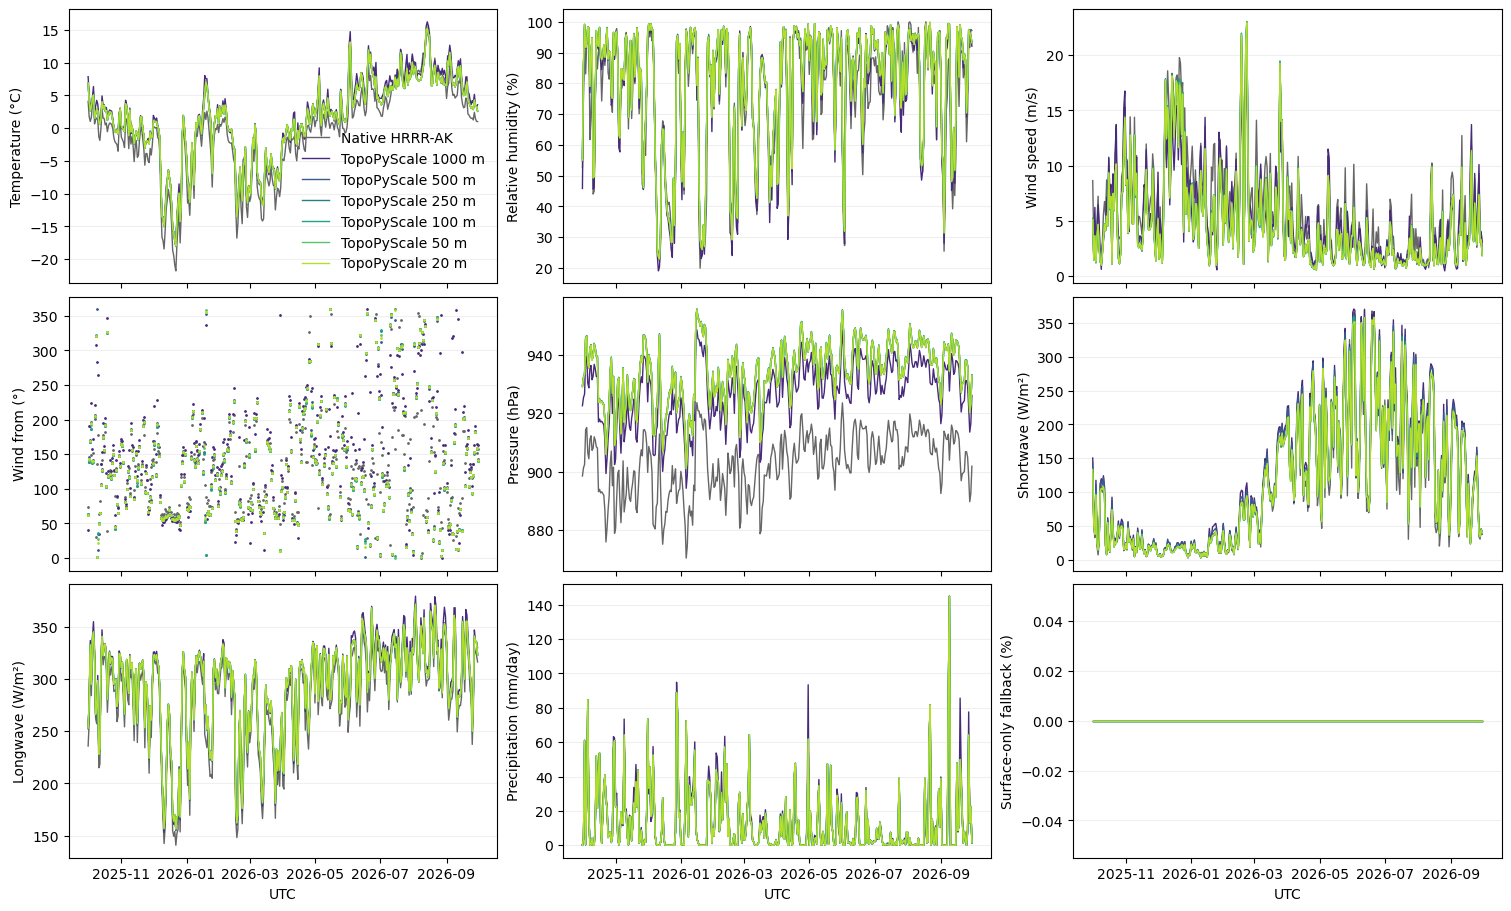

,mean_temperature_C,total_precipitation_mm,fallback_percent
Native HRRR-AK,-0.42,4693.34,NaN
TopoPyScale 1000 m,1.75,4814.79,0.0
TopoPyScale 500 m,1.27,4693.34,0.0
TopoPyScale 250 m,1.22,4693.34,0.0
TopoPyScale 100 m,1.22,4693.34,0.0
TopoPyScale 50 m,1.24,4693.34,0.0
TopoPyScale 20 m,1.25,4693.34,0.0


In [2]:
if ready:
    labels = dict(temperature="Temperature (°C)", rh="Relative humidity (%)",
                  wind="Wind speed (m/s)", wind_direction="Wind from (°)", pressure="Pressure (hPa)",
                  shortwave="Shortwave (W/m²)", longwave="Longwave (W/m²)",
                  precip="Precipitation (mm/day)" if frequency else "Precipitation (mm/hour)",
                  fallback="Surface-only fallback (%)")
    fig, axes = plt.subplots(3,3,sharex=True,figsize=(15,9),layout="constrained")
    for ax, (field, axis_label) in zip(axes.ravel(),labels.items()):
        for (name, data), color in zip(frames.items(), ["#666666", *plt.cm.viridis(np.linspace(.12,.89,len(finished)))]):
            if field not in data:
                continue
            values = data[field]
            if field=="wind_direction" and frequency:
                vector = data[["u_east","v_north"]].resample(frequency).mean()
                values = np.rad2deg(np.arctan2(-vector.u_east,-vector.v_north))%360
            elif frequency:
                grouped = values.resample(frequency)
                values = grouped.sum() if field=="precip" else grouped.mean()
            ax.plot(values.index, values, label=name, color=color,
                    linewidth=0 if field=="wind_direction" else 1,
                    marker="." if field=="wind_direction" else None, markersize=2)
        ax.set_ylabel(axis_label)
        ax.grid(axis="y",alpha=.2)
    axes[0,0].legend(frameon=False)
    for ax in axes[-1,:]:
        ax.set_xlabel("UTC")
    plt.show()
    display(pd.DataFrame({
        label: dict(mean_temperature_C=data.temperature.mean(), total_precipitation_mm=data.precip.sum(),
                    fallback_percent=data.fallback.mean() if "fallback" in data else np.nan)
        for label,data in frames.items()
    }).T.round(2))


In [3]:
if ready and len(finished) >= 2:
    finest = min(finished)
    reference = frames[f"TopoPyScale {finest} m"]
    differences = {}
    for m in finished:
        if m == finest:
            continue
        d = frames[f"TopoPyScale {m} m"] - reference
        differences[f"{m} m"] = {
            "Temperature mean absolute difference (°C)": d.temperature.abs().mean(),
            "Shortwave mean absolute difference (W/m²)": d.shortwave.abs().mean(),
            "Shortwave maximum hourly difference (W/m²)": d.shortwave.abs().max(),
            "Longwave mean absolute difference (W/m²)": d.longwave.abs().mean(),
        }
    print(f"Compared with the finest completed grid ({finest} m)")
    display(pd.DataFrame(differences).T.round(2))


Compared with the finest completed grid (20 m)


,Temperature mean absolute difference (°C),Shortwave mean absolute difference (W/m²),Shortwave maximum hourly difference (W/m²),Longwave mean absolute difference (W/m²)
1000 m,0.65,13.61,237.27,3.80
500 m,0.02,7.43,270.04,0.57
250 m,0.04,1.68,242.91,0.35
100 m,0.04,1.10,248.29,0.27
50 m,0.02,0.59,193.06,0.11
